# 🔬 Eye Disease Classification using Custom GoogleNet

**Dataset Classes:** Cataract, Diabetic Retinopathy, Glaucoma, Normal

**Model Architecture:** Custom GoogleNet (Inception v1)

---

## 📋 Table of Contents
1. Import Libraries
2. Set Parameters
3. Load and Explore Data
4. Visualize Dataset
5. Data Preprocessing
6. Build GoogleNet Model
7. Train Model
8. Evaluate Model
9. Generate ROC Curves
10. Make Predictions

---
## 1️⃣ Import Libraries

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, AveragePooling2D, Dropout, Flatten, Dense,
    BatchNormalization, Activation, concatenate, GlobalAveragePooling2D
)

# Sklearn for metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, 
    precision_score, recall_score, roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize
from sklearn.utils import shuffle
from itertools import cycle



# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")



---
## 2️⃣ Set Parameters and Configuration

In [3]:



DATASET_PATH = r'D:\Downloads\archive 11\dataset'  #

# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
CHANNELS = 3

# Training parameters
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001

# Data split ratios
VALIDATION_SPLIT = 0.15  # 15% for validation
TEST_SPLIT = 0.15        # 15% for testing

# Class names
CLASS_NAMES = ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
NUM_CLASSES = len(CLASS_NAMES)

# Output directory
OUTPUT_DIR = os.path.join(os.getcwd(), 'output')
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'eye_disease_model.h5')
HISTORY_SAVE_PATH = os.path.join(OUTPUT_DIR, 'training_history.json')

# Display configuration
print("="*70)
print("Configuring environment")
print("="*70)
print(f"Dataset Path: {DATASET_PATH}")
print(f"Image Size: {IMG_HEIGHT} × {IMG_WIDTH} × {CHANNELS}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Learning Rate: {LEARNING_RATE}")
print(f"Classes: {CLASS_NAMES}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Output Directory: {OUTPUT_DIR}")
print("="*70)



Configuring environment
Dataset Path: D:\Downloads\archive 11\dataset
Image Size: 224 × 224 × 3
Batch Size: 32
Epochs: 50
Learning Rate: 0.001
Classes: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
Number of Classes: 4
Output Directory: C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output


---
## 3️⃣ Load Dataset

In [5]:
def load_dataset(dataset_path, class_names):

    images = []
    labels = []
    
    print("Loading dataset...\n")
    
    for idx, class_name in enumerate(class_names):
        class_path = os.path.join(dataset_path, class_name)
        
        if not os.path.exists(class_path):
            print(f"⚠ Warning: Directory {class_path} not found!")
            continue
        
        image_files = [f for f in os.listdir(class_path) 
                      if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        print(f" Loading {class_name}: {len(image_files)} images")
        
        for img_file in image_files:
            img_path = os.path.join(class_path, img_file)
            try:
                img = load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
                img_array = img_to_array(img)
                images.append(img_array)
                labels.append(idx)
            except Exception as e:
                print(f" Error loading {img_path}: {e}")
    
    # Convert to numpy arrays and normalize
    images = np.array(images, dtype='float32') / 255.0
    labels = np.array(labels)
    

    print(f"Total images: {len(images):,}")
    print(f"Images shape: {images.shape}")
    print(f"Labels shape: {labels.shape}")
    print(f"Memory usage: {images.nbytes / (1024**2):.2f} MB")
    
    return images, labels

# Load the dataset
if os.path.exists(DATASET_PATH):
    X, y = load_dataset(DATASET_PATH, CLASS_NAMES)
else:
    print(f" WARNING: Dataset path not found: {DATASET_PATH}")
    print("\nCreating dummy dataset for demonstration...")
    X = np.random.rand(400, IMG_HEIGHT, IMG_WIDTH, CHANNELS).astype('float32')
    y = np.random.randint(0, NUM_CLASSES, 400)


Loading dataset...

 Loading cataract: 1038 images
 Loading diabetic_retinopathy: 1098 images
 Loading glaucoma: 1007 images
 Loading normal: 1074 images
Total images: 4,217
Images shape: (4217, 224, 224, 3)
Labels shape: (4217,)
Memory usage: 2421.48 MB


---
## 4️⃣ Visualize Dataset

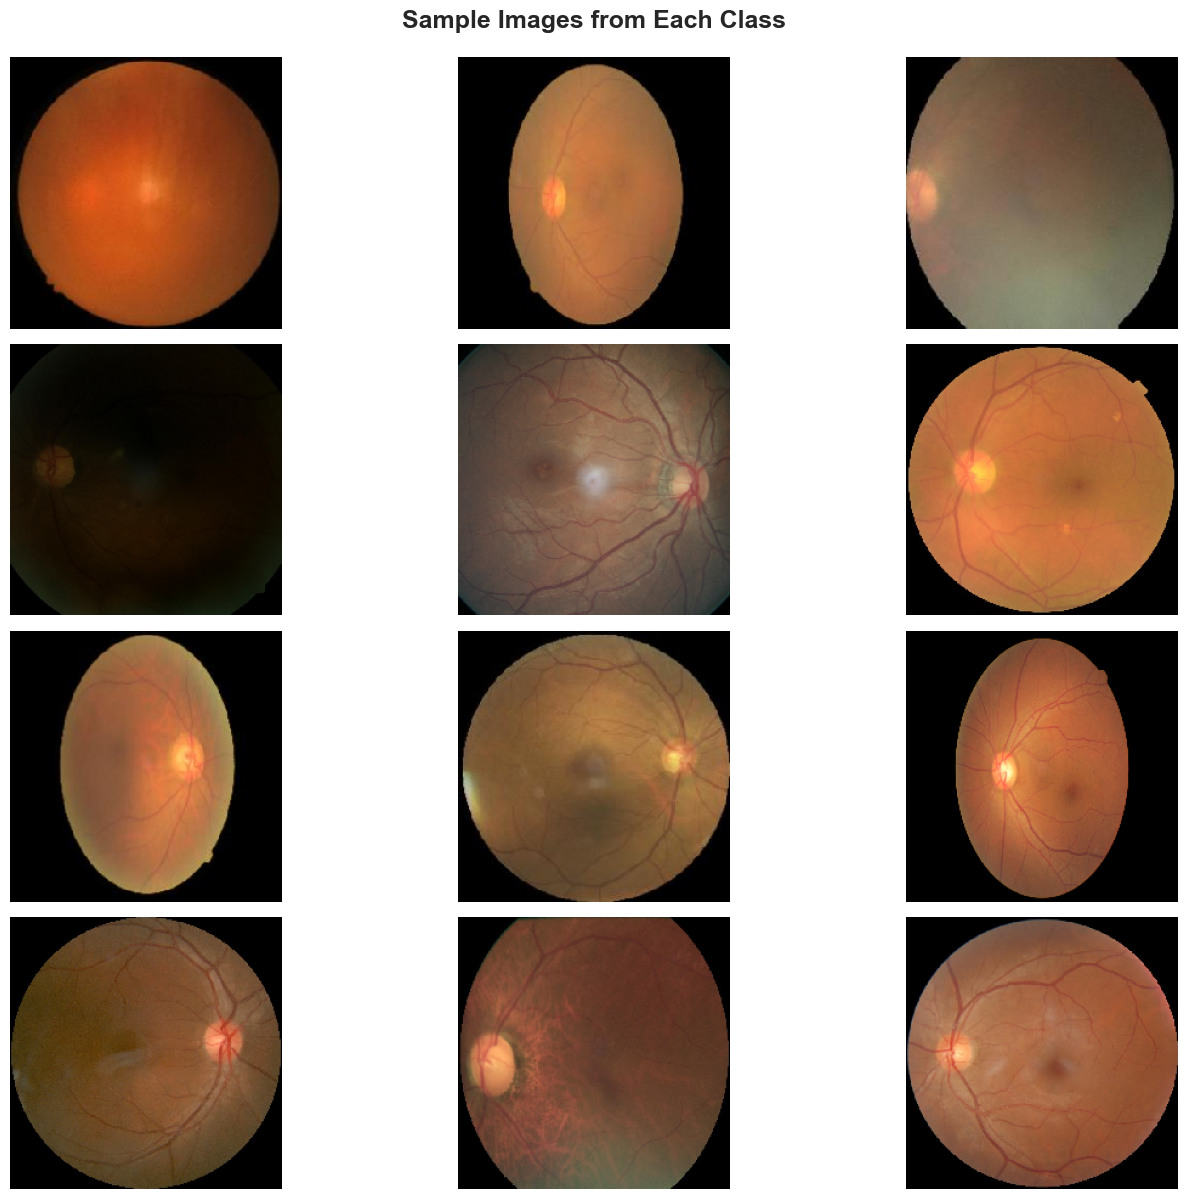

In [6]:
def display_sample_images(images, labels, class_names, samples_per_class=3):

    fig, axes = plt.subplots(len(class_names), samples_per_class, 
                            figsize=(15, 12))
    fig.suptitle('Sample Images from Each Class', fontsize=18, fontweight='bold', y=0.995)
    
    for class_idx in range(len(class_names)):
        class_images = images[labels == class_idx]
        
        if len(class_images) < samples_per_class:
            indices = np.arange(len(class_images))
        else:
            indices = np.random.choice(len(class_images), samples_per_class, replace=False)
        
        for sample_idx in range(min(samples_per_class, len(class_images))):
            ax = axes[class_idx, sample_idx]
            ax.imshow(class_images[indices[sample_idx]])
            ax.axis('off')
            
            if sample_idx == 0:
                ax.set_ylabel(class_names[class_idx].replace('_', ' ').title(), 
                            fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'sample_images.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

# Display sample images
display_sample_images(X, y, CLASS_NAMES)


 CLASS DISTRIBUTION
               Class  Count  Percentage
            cataract   1038       24.61
diabetic_retinopathy   1098       26.04
            glaucoma   1007       23.88
              normal   1074       25.47


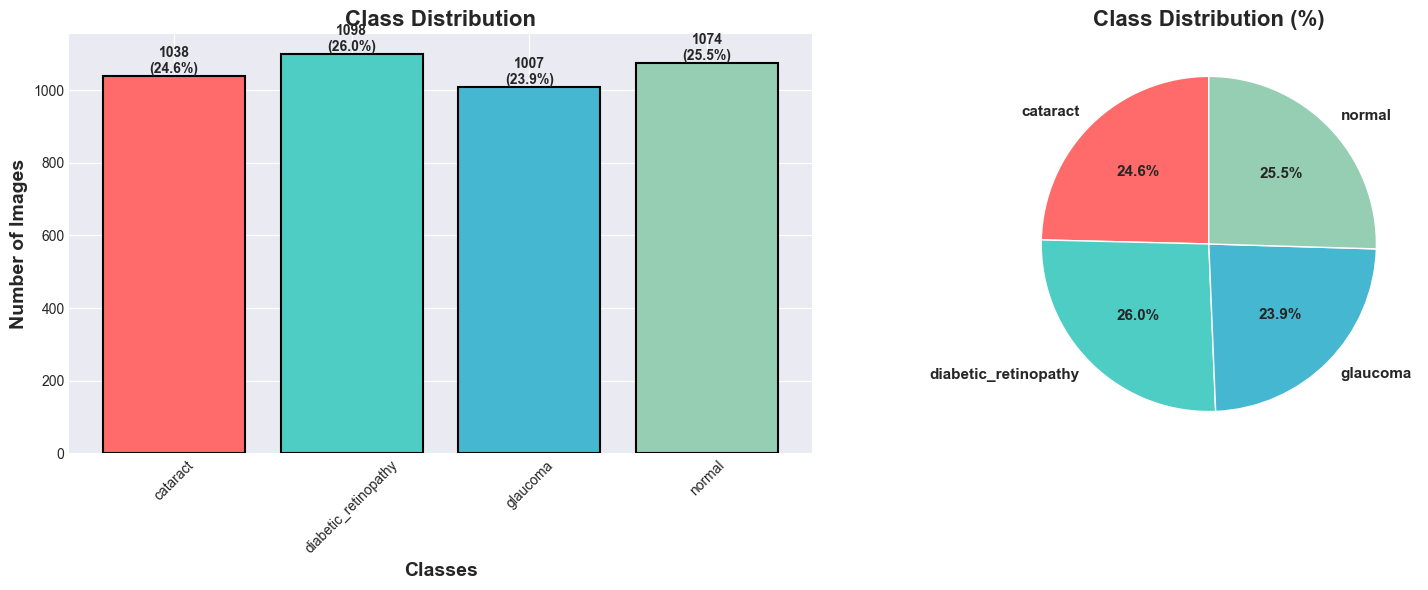

In [7]:
def plot_class_distribution(labels, class_names):

    unique, counts = np.unique(labels, return_counts=True)
    
    # Create DataFrame for better visualization
    df = pd.DataFrame({
        'Class': [class_names[i] for i in unique],
        'Count': counts,
        'Percentage': (counts / len(labels) * 100).round(2)
    })
    
    # Display table
    print("\n" + "="*70)
    print(" CLASS DISTRIBUTION")
    print("="*70)
    print(df.to_string(index=False))
    print("="*70)
    
    # Create bar plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Bar chart
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    bars = ax1.bar(class_names, counts, color=colors, edgecolor='black', linewidth=1.5)
    ax1.set_xlabel('Classes', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Number of Images', fontsize=14, fontweight='bold')
    ax1.set_title('Class Distribution', fontsize=16, fontweight='bold')
    ax1.tick_params(axis='x', rotation=45)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}\n({height/len(labels)*100:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    # Pie chart
    ax2.pie(counts, labels=class_names, autopct='%1.1f%%', 
           colors=colors, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
    ax2.set_title('Class Distribution (%)', fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'class_distribution.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

# Plot class distribution
plot_class_distribution(y, CLASS_NAMES)

---
## 5️⃣ Data Preprocessing and Splitting

In [9]:
# Shuffle the data
X, y = shuffle(X, y, random_state=42)



# Split: Train (70%), Validation (15%), Test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=(VALIDATION_SPLIT + TEST_SPLIT), 
    random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, 
    random_state=42, stratify=y_temp
)

print(f"Training set: {X_train.shape[0]:,} images ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]:,} images ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]:,} images ({X_test.shape[0]/len(X)*100:.1f}%)")

# Convert labels to categorical (one-hot encoding)
y_train_cat = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat = keras.utils.to_categorical(y_test, NUM_CLASSES)

print(f"\nTraining labels shape: {y_train_cat.shape}")
print(f"Validation labels shape: {y_val_cat.shape}")
print(f"Test labels shape: {y_test_cat.shape}")

# Display distribution in each set
print("\n" + "="*70)
print(" CLASS DISTRIBUTION IN SPLITS")
print("="*70)

split_df = pd.DataFrame({
    'Class': CLASS_NAMES,
    'Train': [np.sum(y_train == i) for i in range(NUM_CLASSES)],
    'Validation': [np.sum(y_val == i) for i in range(NUM_CLASSES)],
    'Test': [np.sum(y_test == i) for i in range(NUM_CLASSES)]
})
print(split_df.to_string(index=False))
print("="*70)



Training set: 2,951 images (70.0%)
Validation set: 633 images (15.0%)
Test set: 633 images (15.0%)

Training labels shape: (2951, 4)
Validation labels shape: (633, 4)
Test labels shape: (633, 4)

 CLASS DISTRIBUTION IN SPLITS
               Class  Train  Validation  Test
            cataract    726         156   156
diabetic_retinopathy    768         165   165
            glaucoma    705         151   151
              normal    752         161   161


---
## 6️⃣ Build Custom GoogleNet Model

In [10]:
def inception_module(x, filters_1x1, filters_3x3_reduce, filters_3x3,
                     filters_5x5_reduce, filters_5x5, filters_pool_proj, name=None):

    # 1x1 convolution branch
    conv_1x1 = Conv2D(filters_1x1, (1, 1), padding='same', activation='relu',
                      name=f'{name}_1x1' if name else None)(x)
    
    # 3x3 convolution branch (with dimension reduction)
    conv_3x3 = Conv2D(filters_3x3_reduce, (1, 1), padding='same', activation='relu',
                      name=f'{name}_3x3_reduce' if name else None)(x)
    conv_3x3 = Conv2D(filters_3x3, (3, 3), padding='same', activation='relu',
                      name=f'{name}_3x3' if name else None)(conv_3x3)
    
    # 5x5 convolution branch (with dimension reduction)
    conv_5x5 = Conv2D(filters_5x5_reduce, (1, 1), padding='same', activation='relu',
                      name=f'{name}_5x5_reduce' if name else None)(x)
    conv_5x5 = Conv2D(filters_5x5, (5, 5), padding='same', activation='relu',
                      name=f'{name}_5x5' if name else None)(conv_5x5)
    
    # Max pooling branch (with projection)
    pool_proj = MaxPooling2D((3, 3), strides=(1, 1), padding='same',
                             name=f'{name}_pool' if name else None)(x)
    pool_proj = Conv2D(filters_pool_proj, (1, 1), padding='same', activation='relu',
                       name=f'{name}_pool_proj' if name else None)(pool_proj)
    
    # Concatenate all branches
    output = concatenate([conv_1x1, conv_3x3, conv_5x5, pool_proj], axis=-1,
                         name=f'{name}_concat' if name else None)
    
    return output


def build_custom_googlenet(input_shape, num_classes):

    input_layer = Input(shape=input_shape, name='input')
    
    # Initial convolution layers
    x = Conv2D(64, (7, 7), strides=(2, 2), padding='same', activation='relu', name='conv1_7x7')(input_layer)
    x = MaxPooling2D((3, 3), strides=(2, 2), padding='same', name='pool1')(x)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (1, 1), padding='same', activation='relu', name='conv2_1x1')(x)
    x = Conv2D(192, (3, 3), padding='same', activation='relu', name='conv2_3x3')(x)
    x = MaxPooling2D((3, 3), strides=(2, 2), padding='same', name='pool2')(x)
    x = BatchNormalization()(x)
    
    # Inception modules 3a and 3b
    x = inception_module(x, 64, 96, 128, 16, 32, 32, name='inception_3a')
    x = inception_module(x, 128, 128, 192, 32, 96, 64, name='inception_3b')
    x = MaxPooling2D((3, 3), strides=(2, 2), padding='same', name='pool3')(x)
    
    # Inception modules 4a, 4b, 4c, 4d, 4e
    x = inception_module(x, 192, 96, 208, 16, 48, 64, name='inception_4a')
    x = inception_module(x, 160, 112, 224, 24, 64, 64, name='inception_4b')
    x = inception_module(x, 128, 128, 256, 24, 64, 64, name='inception_4c')
    x = inception_module(x, 112, 144, 288, 32, 64, 64, name='inception_4d')
    x = inception_module(x, 256, 160, 320, 32, 128, 128, name='inception_4e')
    x = MaxPooling2D((3, 3), strides=(2, 2), padding='same', name='pool4')(x)
    
    # Inception modules 5a and 5b
    x = inception_module(x, 256, 160, 320, 32, 128, 128, name='inception_5a')
    x = inception_module(x, 384, 192, 384, 48, 128, 128, name='inception_5b')
    
    # Global Average Pooling
    x = GlobalAveragePooling2D(name='global_avg_pool')(x)
    x = Dropout(0.4, name='dropout')(x)
    
    # Output layer
    output = Dense(num_classes, activation='softmax', name='output')(x)
    
    # Create model
    model = Model(inputs=input_layer, outputs=output, name='CustomGoogleNet')
    
    return model


# Build the model
print("="*70)
print(" BUILDING CUSTOM GOOGLENET MODEL")
print("="*70)

model = build_custom_googlenet(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    num_classes=NUM_CLASSES
)

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



model.summary()

# Calculate total parameters
total_params = model.count_params()
trainable_params = sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = total_params - trainable_params

print("\n" + "="*70)
print(" MODEL STATISTICS")
print("="*70)
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Non-trainable Parameters: {non_trainable_params:,}")
print(f"Estimated Model Size: ~{total_params * 4 / (1024**2):.1f} MB")
print("="*70)

 BUILDING CUSTOM GOOGLENET MODEL


Model: "CustomGoogleNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_7x7 (Conv2D)  │ (None, 112, 112,  │      9,472 │ input[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ conv1_7x7[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_1x1 (Conv2D)  │ (None, 56, 56,    │      4,160 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_3x3 (Conv2D)  │ (None, 56, 56,    │    110,784 │ conv2_1x1[0][0]   │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 28, 28,    │          0 │ conv2_3x3[0][0]   │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        768 │ pool2[0][0]       │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3_r… │ (None, 28, 28,    │     18,528 │ batch_normalizat… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5_r… │ (None, 28, 28,    │      3,088 │ batch_normalizat… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool   │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_1x1    │ (None, 28, 28,    │     12,352 │ batch_normalizat… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3    │ (None, 28, 28,    │    110,720 │ inception_3a_3x3… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5    │ (None, 28, 28,    │     12,832 │ inception_3a_5x5… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool_… │ (None, 28, 28,    │      6,176 │ inception_3a_poo… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_concat │ (None, 28, 28,    │          0 │ inception_3a_1x1… │
│ (Concatenate)       │ 256)              │            │ inception_3a_3x3… │
│                     │                   │            │ inception_3a_5x5… │
│                     │                   │            │ inception_3a_poo

 Total params: 5,978,676 (22.81 MB)

 Trainable params: 5,978,164 (22.80 MB)

 Non-trainable params: 512 (2.00 KB)


 MODEL STATISTICS
Total Parameters: 5,978,676
Trainable Parameters: 5,978,164
Non-trainable Parameters: 512
Estimated Model Size: ~22.8 MB


---
## 7️⃣ Setup Data Augmentation and Callbacks

In [11]:
# Data Augmentation


datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.2,
    fill_mode='nearest'
)

checkpoint = ModelCheckpoint(
    MODEL_SAVE_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stop, reduce_lr]



---
## 8️⃣ Train the Model

⚠️ **Note:** Training may take 2-4 hours on CPU or 20-40 minutes on GPU

In [10]:
print("="*70)
print("🚀 TRAINING MODEL")
print("="*70)
print(f"Training for {EPOCHS} epochs with batch size {BATCH_SIZE}")
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("="*70)
print("\n⏳ Training in progress... Please wait...\n")

# Train the model
history = model.fit(
    datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE),
    validation_data=(X_val, y_val_cat),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print(f"\n{'='*70}")
print(f"✅ Training completed at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*70}")

# Save training history
history_dict = {
    'accuracy': [float(x) for x in history.history['accuracy']],
    'val_accuracy': [float(x) for x in history.history['val_accuracy']],
    'loss': [float(x) for x in history.history['loss']],
    'val_loss': [float(x) for x in history.history['val_loss']]
}

with open(HISTORY_SAVE_PATH, 'w') as f:
    json.dump(history_dict, f, indent=4)

print(f"\n💾 Training history saved to: {HISTORY_SAVE_PATH}")
print(f"💾 Best model saved to: {MODEL_SAVE_PATH}")

🚀 TRAINING MODEL
Training for 50 epochs with batch size 32
Started at: 2025-10-11 23:36:28

⏳ Training in progress... Please wait...

Epoch 1/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.2763 - loss: 1.4671
Epoch 1: val_accuracy improved from None to 0.26066, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 53s 480ms/step - accuracy: 0.3084 - loss: 1.3918 - val_accuracy: 0.2607 - val_loss: 1.4714 - learning_rate: 0.0010
Epoch 2/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.3951 - loss: 1.2477
Epoch 2: val_accuracy did not improve from 0.26066
93/93 ━━━━━━━━━━━━━━━━━━━━ 52s 559ms/step - accuracy: 0.4158 - loss: 1.2205 - val_accuracy: 0.2607 - val_loss: 2.2619 - learning_rate: 0.0010
Epoch 3/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.4204 - loss: 1.1720
Epoch 3: val_accuracy did not improve from 0.26066
93/93 ━━━━━━━━━━━━━━━━━━━━ 54s 580ms/step - accuracy: 0.4676 - loss: 1.1214 - val_accuracy: 0.2607 - val_loss: 4.0147 - learning_rate: 0.0010
Epoch 4/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.5438 - loss: 1.0267
Epoch 4: val_accuracy improved from 0.26066 to 0.26540, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 60s 642ms/step - accuracy: 0.5517 - loss: 0.9990 - val_accuracy: 0.2654 - val_loss: 3.4588 - learning_rate: 0.0010
Epoch 5/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 584ms/step - accuracy: 0.5806 - loss: 0.9312
Epoch 5: val_accuracy improved from 0.26540 to 0.26856, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 58s 619ms/step - accuracy: 0.6001 - loss: 0.9200 - val_accuracy: 0.2686 - val_loss: 2.5173 - learning_rate: 0.0010
Epoch 6/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - accuracy: 0.6215 - loss: 0.8932
Epoch 6: val_accuracy improved from 0.26856 to 0.55608, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 56s 605ms/step - accuracy: 0.6181 - loss: 0.8845 - val_accuracy: 0.5561 - val_loss: 1.0398 - learning_rate: 0.0010
Epoch 7/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 583ms/step - accuracy: 0.6146 - loss: 0.8473
Epoch 7: val_accuracy did not improve from 0.55608
93/93 ━━━━━━━━━━━━━━━━━━━━ 58s 620ms/step - accuracy: 0.6405 - loss: 0.8271 - val_accuracy: 0.4566 - val_loss: 1.0241 - learning_rate: 0.0010
Epoch 8/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.6457 - loss: 0.8235
Epoch 8: val_accuracy improved from 0.55608 to 0.56872, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


...

93/93 ━━━━━━━━━━━━━━━━━━━━ 48s 512ms/step - accuracy: 0.7103 - loss: 0.7118 - val_accuracy: 0.6430 - val_loss: 0.9552 - learning_rate: 0.0010
Epoch 14/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - accuracy: 0.7269 - loss: 0.6847
Epoch 14: val_accuracy did not improve from 0.64297

Epoch 14: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
93/93 ━━━━━━━━━━━━━━━━━━━━ 54s 579ms/step - accuracy: 0.7381 - loss: 0.6568 - val_accuracy: 0.4866 - val_loss: 1.2654 - learning_rate: 0.0010
Epoch 15/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step - accuracy: 0.7731 - loss: 0.5932
Epoch 15: val_accuracy improved from 0.64297 to 0.75829, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 46s 499ms/step - accuracy: 0.7848 - loss: 0.5661 - val_accuracy: 0.7583 - val_loss: 0.7187 - learning_rate: 5.0000e-04
Epoch 16/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.8141 - loss: 0.4982
Epoch 16: val_accuracy did not improve from 0.75829
93/93 ━━━━━━━━━━━━━━━━━━━━ 57s 611ms/step - accuracy: 0.7984 - loss: 0.5169 - val_accuracy: 0.7457 - val_loss: 0.6520 - learning_rate: 5.0000e-04
Epoch 17/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.8031 - loss: 0.5044
Epoch 17: val_accuracy did not improve from 0.75829
93/93 ━━━━━━━━━━━━━━━━━━━━ 46s 494ms/step - accuracy: 0.8109 - loss: 0.4957 - val_accuracy: 0.7409 - val_loss: 0.6477 - learning_rate: 5.0000e-04
Epoch 18/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.8219 - loss: 0.4430
Epoch 18: val_accuracy did not improve from 0.75829
93/93 ━━━━━━━━━━━━━━━━━━━━ 46s 494ms/step - accuracy: 0.8136 - loss: 0.4679 - val_accuracy: 0.7062 - val_loss: 0.7596 - learning_rate: 5.0000e-04

93/93 ━━━━━━━━━━━━━━━━━━━━ 41s 438ms/step - accuracy: 0.8350 - loss: 0.4284 - val_accuracy: 0.7709 - val_loss: 0.5801 - learning_rate: 5.0000e-04
Epoch 22/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.8334 - loss: 0.4196
Epoch 22: val_accuracy improved from 0.77093 to 0.78199, saving model to C:\Users\akaka\OneDrive\Desktop\jjjjjjjjjjjjjjjk\output\eye_disease_model.h5


93/93 ━━━━━━━━━━━━━━━━━━━━ 47s 510ms/step - accuracy: 0.8370 - loss: 0.4090 - val_accuracy: 0.7820 - val_loss: 0.5587 - learning_rate: 5.0000e-04
Epoch 23/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.8419 - loss: 0.4074
Epoch 23: val_accuracy did not improve from 0.78199
93/93 ━━━━━━━━━━━━━━━━━━━━ 46s 491ms/step - accuracy: 0.8407 - loss: 0.4121 - val_accuracy: 0.6951 - val_loss: 0.6967 - learning_rate: 5.0000e-04
Epoch 24/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.8477 - loss: 0.3753
Epoch 24: val_accuracy did not improve from 0.78199
93/93 ━━━━━━━━━━━━━━━━━━━━ 42s 451ms/step - accuracy: 0.8499 - loss: 0.3876 - val_accuracy: 0.7804 - val_loss: 0.5636 - learning_rate: 5.0000e-04
Epoch 25/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.8406 - loss: 0.3777
Epoch 25: val_accuracy did not improve from 0.78199
93/93 ━━━━━━━━━━━━━━━━━━━━ 40s 433ms/step - accuracy: 0.8445 - loss: 0.3917 - val_accuracy: 0.6967 - val_loss: 0.8093 - learning_rate: 5.0000e-04

93/93 ━━━━━━━━━━━━━━━━━━━━ 44s 468ms/step - accuracy: 0.8763 - loss: 0.3096 - val_accuracy: 0.8073 - val_loss: 0.5144 - learning_rate: 2.5000e-04
Epoch 29/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.8784 - loss: 0.2992
Epoch 29: val_accuracy did not improve from 0.80727
93/93 ━━━━━━━━━━━━━━━━━━━━ 45s 480ms/step - accuracy: 0.8722 - loss: 0.3127 - val_accuracy: 0.7741 - val_loss: 0.5767 - learning_rate: 2.5000e-04
Epoch 30/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.8821 - loss: 0.2905
Epoch 30: val_accuracy did not improve from 0.80727
93/93 ━━━━━━━━━━━━━━━━━━━━ 41s 444ms/step - accuracy: 0.8790 - loss: 0.3000 - val_accuracy: 0.7093 - val_loss: 0.7769 - learning_rate: 2.5000e-04
Epoch 31/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.8696 - loss: 0.3275
Epoch 31: val_accuracy did not improve from 0.80727
93/93 ━━━━━━━━━━━━━━━━━━━━ 42s 447ms/step - accuracy: 0.8743 - loss: 0.3116 - val_accuracy: 0.6651 - val_loss: 0.8560 - learning_rate: 2.5000e-04

---
## 9️⃣ Plot Training History

In [16]:
best_model = tf.keras.models.load_model(MODEL_SAVE_PATH)
model = best_model

# Load the training history from the JSON file
with open(HISTORY_SAVE_PATH, 'r') as f:
    history_dict = json.load(f)

# Evaluate on test set to get loss and accuracy
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

# Make predictions for confusion matrix, reports, and ROC curve
y_pred = model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)

# The confusion matrix, classification report, and some plots need integer labels
y_test_classes = np.argmax(y_test_cat, axis=1)


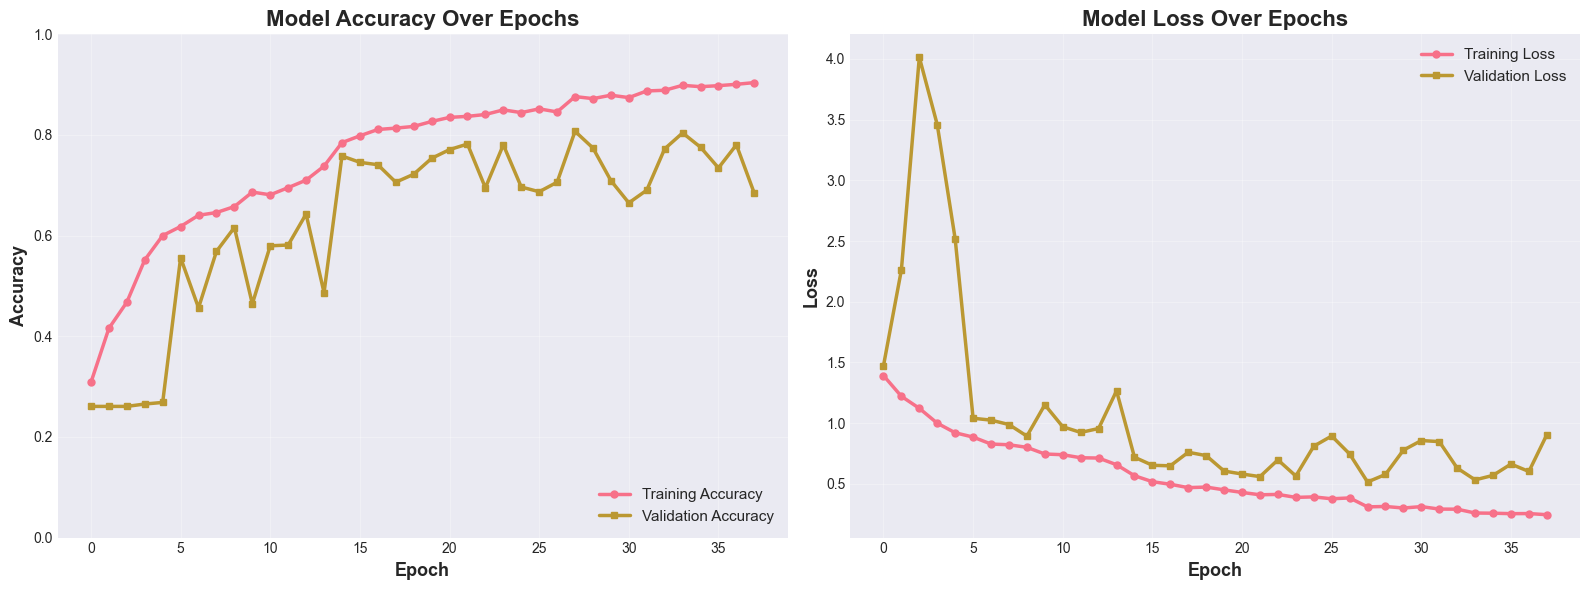


 FINAL TRAINING METRICS
Final Training Accuracy: 0.9041 (90.41%)
Final Validation Accuracy: 0.6840 (68.40%)
Final Training Loss: 0.2449
Final Validation Loss: 0.9039
Best Validation Accuracy: 0.8073 (80.73%)


In [17]:
def plot_training_history(history):

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Accuracy plot
    axes[0].plot(history['accuracy'], label='Training Accuracy', 
                linewidth=2.5, marker='o', markersize=5)
    axes[0].plot(history['val_accuracy'], label='Validation Accuracy', 
                linewidth=2.5, marker='s', markersize=5)
    axes[0].set_title('Model Accuracy Over Epochs', fontsize=16, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Accuracy', fontsize=13, fontweight='bold')
    axes[0].legend(loc='lower right', fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])
    
    # Loss plot
    axes[1].plot(history['loss'], label='Training Loss', 
                linewidth=2.5, marker='o', markersize=5)
    axes[1].plot(history['val_loss'], label='Validation Loss', 
                linewidth=2.5, marker='s', markersize=5)
    axes[1].set_title('Model Loss Over Epochs', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Loss', fontsize=13, fontweight='bold')
    axes[1].legend(loc='upper right', fontsize=11)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'training_history.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()
    
    # Print final metrics
    print("\n" + "="*70)
    print(" FINAL TRAINING METRICS")
    print("="*70)
    print(f"Final Training Accuracy: {history['accuracy'][-1]:.4f} ({history['accuracy'][-1]*100:.2f}%)")
    print(f"Final Validation Accuracy: {history['val_accuracy'][-1]:.4f} ({history['val_accuracy'][-1]*100:.2f}%)")
    print(f"Final Training Loss: {history['loss'][-1]:.4f}")
    print(f"Final Validation Loss: {history['val_loss'][-1]:.4f}")
    print(f"Best Validation Accuracy: {max(history['val_accuracy']):.4f} ({max(history['val_accuracy'])*100:.2f}%)")
    print("="*70)

# Plot training history
plot_training_history(history_dict)

---
## 🔟 Evaluate Model on Test Set

In [18]:
print("="*70)
print(" EVALUATING MODEL ON TEST SET")
print("="*70)

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

# Make predictions

y_pred = model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)



 EVALUATING MODEL ON TEST SET

Test Loss: 0.4770
Test Accuracy: 0.8167 (81.67%)


---
## 1️⃣1️⃣ Confusion Matrix


 GENERATING CONFUSION MATRIX


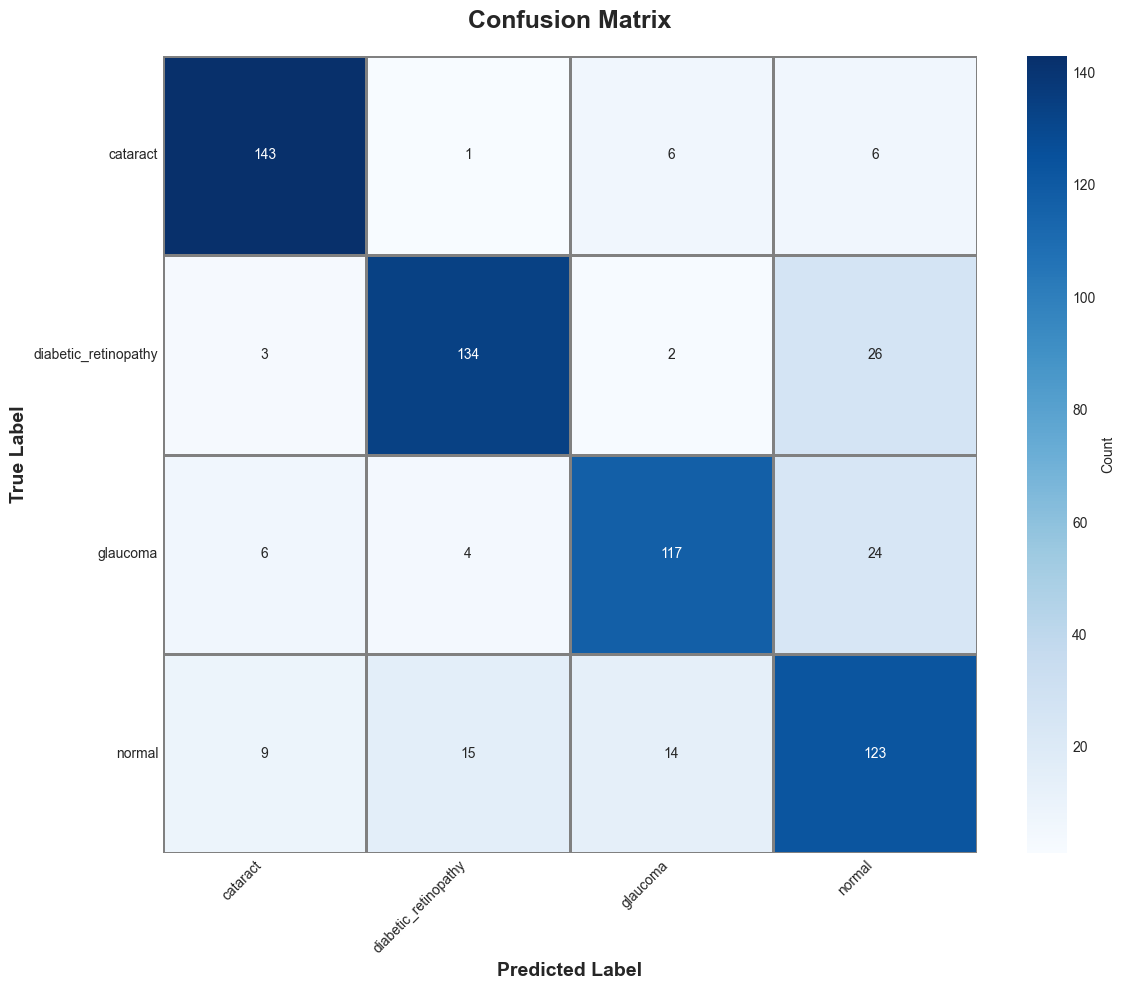


 PER-CLASS ACCURACY FROM CONFUSION MATRIX
cataract                 :  91.67% (143/156 correct)
diabetic_retinopathy     :  81.21% (134/165 correct)
glaucoma                 :  77.48% (117/151 correct)
normal                   :  76.40% (123/161 correct)
Overall Accuracy         :  81.67%


In [19]:
def plot_confusion_matrix(y_true, y_pred, class_names):

    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'}, linewidths=1, linecolor='gray')
    plt.title('Confusion Matrix', fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Label', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    
    save_path = os.path.join(OUTPUT_DIR, 'confusion_matrix.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    # Calculate and display per-class accuracy
    print("\n" + "="*70)
    print(" PER-CLASS ACCURACY FROM CONFUSION MATRIX")
    print("="*70)
    
    for i, class_name in enumerate(class_names):
        class_accuracy = cm[i, i] / np.sum(cm[i, :]) * 100
        print(f"{class_name:25s}: {class_accuracy:6.2f}% ({cm[i, i]}/{np.sum(cm[i, :])} correct)")
    
    overall_accuracy = np.trace(cm) / np.sum(cm) * 100
    print(f"{'Overall Accuracy':25s}: {overall_accuracy:6.2f}%")
    print("="*70)
    
    return cm

# Plot confusion matrix
print("\n" + "="*70)
print(" GENERATING CONFUSION MATRIX")
print("="*70)
cm = plot_confusion_matrix(y_test, y_pred_classes, CLASS_NAMES)

---
## 1️⃣2️⃣ Classification Report

In [20]:
def generate_classification_report(y_true, y_pred, class_names):

    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    
    print("\n" + "="*70)
    print(" CLASSIFICATION REPORT")
    print("="*70)
    print(report)
    
    # Save to file
    report_path = os.path.join(OUTPUT_DIR, 'classification_report.txt')
    with open(report_path, 'w') as f:
        f.write("Classification Report\n")
        f.write("="*70 + "\n")
        f.write(report)
    
    # Create detailed metrics DataFrame
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()
    
    csv_path = os.path.join(OUTPUT_DIR, 'classification_metrics.csv')
    df_report.to_csv(csv_path)
    

    
    return report

# Generate classification report
report = generate_classification_report(y_test, y_pred_classes, CLASS_NAMES)


 CLASSIFICATION REPORT
                      precision    recall  f1-score   support

            cataract     0.8882    0.9167    0.9022       156
diabetic_retinopathy     0.8701    0.8121    0.8401       165
            glaucoma     0.8417    0.7748    0.8069       151
              normal     0.6872    0.7640    0.7235       161

            accuracy                         0.8167       633
           macro avg     0.8218    0.8169    0.8182       633
        weighted avg     0.8213    0.8167    0.8178       633



---
## 1️⃣3️⃣ Additional Metrics

 ADDITIONAL METRICS

Macro-averaged metrics:
  F1-Score: 0.8182
  Precision: 0.8218
  Recall: 0.8169

Weighted-averaged metrics:
  F1-Score: 0.8178
  Precision: 0.8213
  Recall: 0.8167



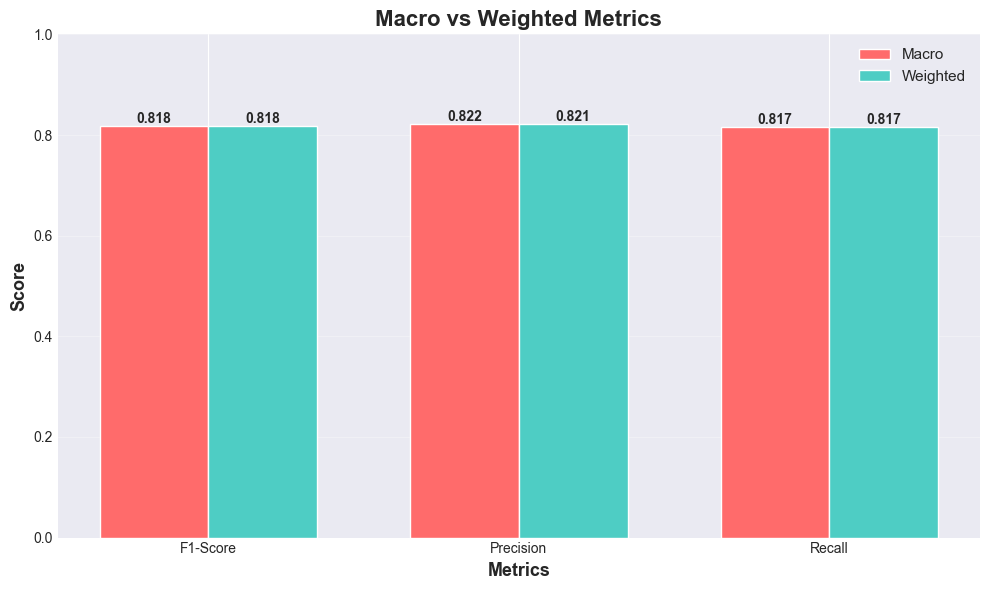

In [22]:
print("="*70)
print(" ADDITIONAL METRICS")
print("="*70)

# Calculate additional metrics
f1_macro = f1_score(y_test, y_pred_classes, average='macro')
f1_weighted = f1_score(y_test, y_pred_classes, average='weighted')
precision_macro = precision_score(y_test, y_pred_classes, average='macro')
precision_weighted = precision_score(y_test, y_pred_classes, average='weighted')
recall_macro = recall_score(y_test, y_pred_classes, average='macro')
recall_weighted = recall_score(y_test, y_pred_classes, average='weighted')

print(f"\nMacro-averaged metrics:")
print(f"  F1-Score: {f1_macro:.4f}")
print(f"  Precision: {precision_macro:.4f}")
print(f"  Recall: {recall_macro:.4f}")

print(f"\nWeighted-averaged metrics:")
print(f"  F1-Score: {f1_weighted:.4f}")
print(f"  Precision: {precision_weighted:.4f}")
print(f"  Recall: {recall_weighted:.4f}")

print("\n" + "="*70)

# Create metrics visualization
metrics_data = {
    'Metric': ['F1-Score', 'Precision', 'Recall'],
    'Macro': [f1_macro, precision_macro, recall_macro],
    'Weighted': [f1_weighted, precision_weighted, recall_weighted]
}

df_metrics = pd.DataFrame(metrics_data)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(df_metrics['Metric']))
width = 0.35

bars1 = ax.bar(x - width/2, df_metrics['Macro'], width, label='Macro', color='#FF6B6B')
bars2 = ax.bar(x + width/2, df_metrics['Weighted'], width, label='Weighted', color='#4ECDC4')

ax.set_xlabel('Metrics', fontsize=13, fontweight='bold')
ax.set_ylabel('Score', fontsize=13, fontweight='bold')
ax.set_title('Macro vs Weighted Metrics', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_metrics['Metric'])
ax.legend(fontsize=11)
ax.set_ylim([0, 1])
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, 'additional_metrics.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show()

---
## 1️⃣4️⃣ ROC Curves and AUC Scores

ROC (Receiver Operating Characteristic) curves show the trade-off between True Positive Rate and False Positive Rate


 GENERATING ROC CURVES


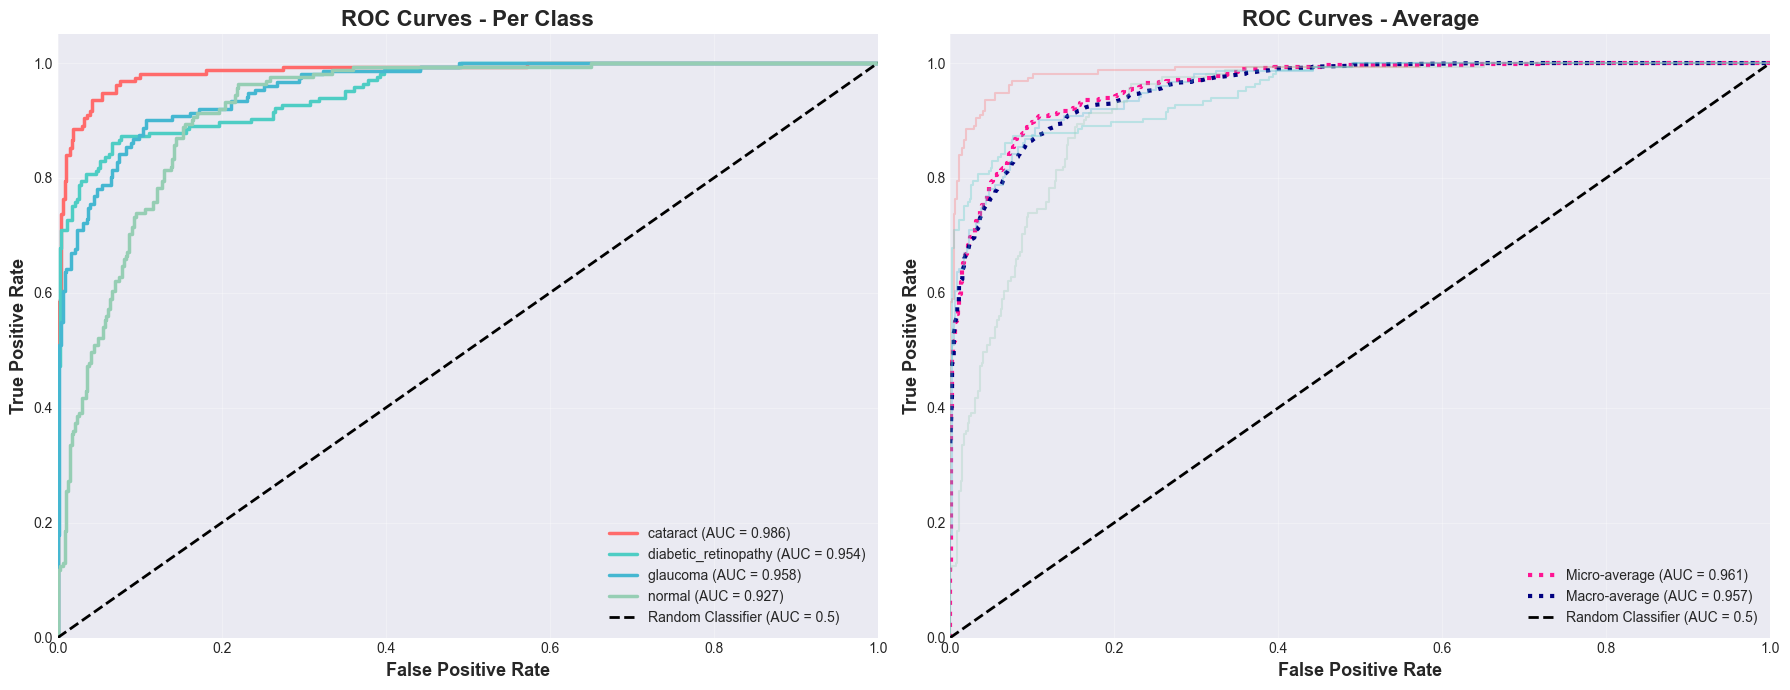


 AUC (Area Under Curve) SCORES
cataract                 : 0.9859
diabetic_retinopathy     : 0.9541
glaucoma                 : 0.9582
normal                   : 0.9274
Micro-average            : 0.9613
Macro-average            : 0.9572


In [23]:
def plot_roc_curves(y_test, y_pred, class_names):

    # Binarize the labels for multi-class ROC
    y_test_bin = label_binarize(y_test, classes=range(NUM_CLASSES))
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    for i in range(NUM_CLASSES):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_pred.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    # Compute macro-average ROC curve and ROC area
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(NUM_CLASSES)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(NUM_CLASSES):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= NUM_CLASSES
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
    
    # Plot all ROC curves
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    
    # Plot 1: Individual class ROC curves
    colors = cycle(['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
    for i, color in zip(range(NUM_CLASSES), colors):
        ax1.plot(fpr[i], tpr[i], color=color, lw=2.5,
                label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})')
    
    ax1.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.5)')
    ax1.set_xlim([0.0, 1.0])
    ax1.set_ylim([0.0, 1.05])
    ax1.set_xlabel('False Positive Rate', fontsize=13, fontweight='bold')
    ax1.set_ylabel('True Positive Rate', fontsize=13, fontweight='bold')
    ax1.set_title('ROC Curves - Per Class', fontsize=16, fontweight='bold')
    ax1.legend(loc="lower right", fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Macro and Micro average ROC curves
    ax2.plot(fpr["micro"], tpr["micro"],
            label=f'Micro-average (AUC = {roc_auc["micro"]:.3f})',
            color='deeppink', linestyle=':', linewidth=3)
    
    ax2.plot(fpr["macro"], tpr["macro"],
            label=f'Macro-average (AUC = {roc_auc["macro"]:.3f})',
            color='navy', linestyle=':', linewidth=3)
    
    # Plot all individual curves in lighter shade
    colors = cycle(['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
    for i, color in zip(range(NUM_CLASSES), colors):
        ax2.plot(fpr[i], tpr[i], color=color, lw=1.5, alpha=0.3)
    
    ax2.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.5)')
    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.05])
    ax2.set_xlabel('False Positive Rate', fontsize=13, fontweight='bold')
    ax2.set_ylabel('True Positive Rate', fontsize=13, fontweight='bold')
    ax2.set_title('ROC Curves - Average', fontsize=16, fontweight='bold')
    ax2.legend(loc="lower right", fontsize=10)
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'roc_curves.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()
    
    # Print AUC scores
    print("\n" + "="*70)
    print(" AUC (Area Under Curve) SCORES")
    print("="*70)
    for i, class_name in enumerate(class_names):
        print(f"{class_name:25s}: {roc_auc[i]:.4f}")
    print(f"{'Micro-average':25s}: {roc_auc['micro']:.4f}")
    print(f"{'Macro-average':25s}: {roc_auc['macro']:.4f}")
    print("="*70)
    
    return roc_auc

# Plot ROC curves
print("\n" + "="*70)
print(" GENERATING ROC CURVES")
print("="*70)
roc_auc_scores = plot_roc_curves(y_test, y_pred, CLASS_NAMES)

---
## 1️⃣5️⃣ Visualize Predictions

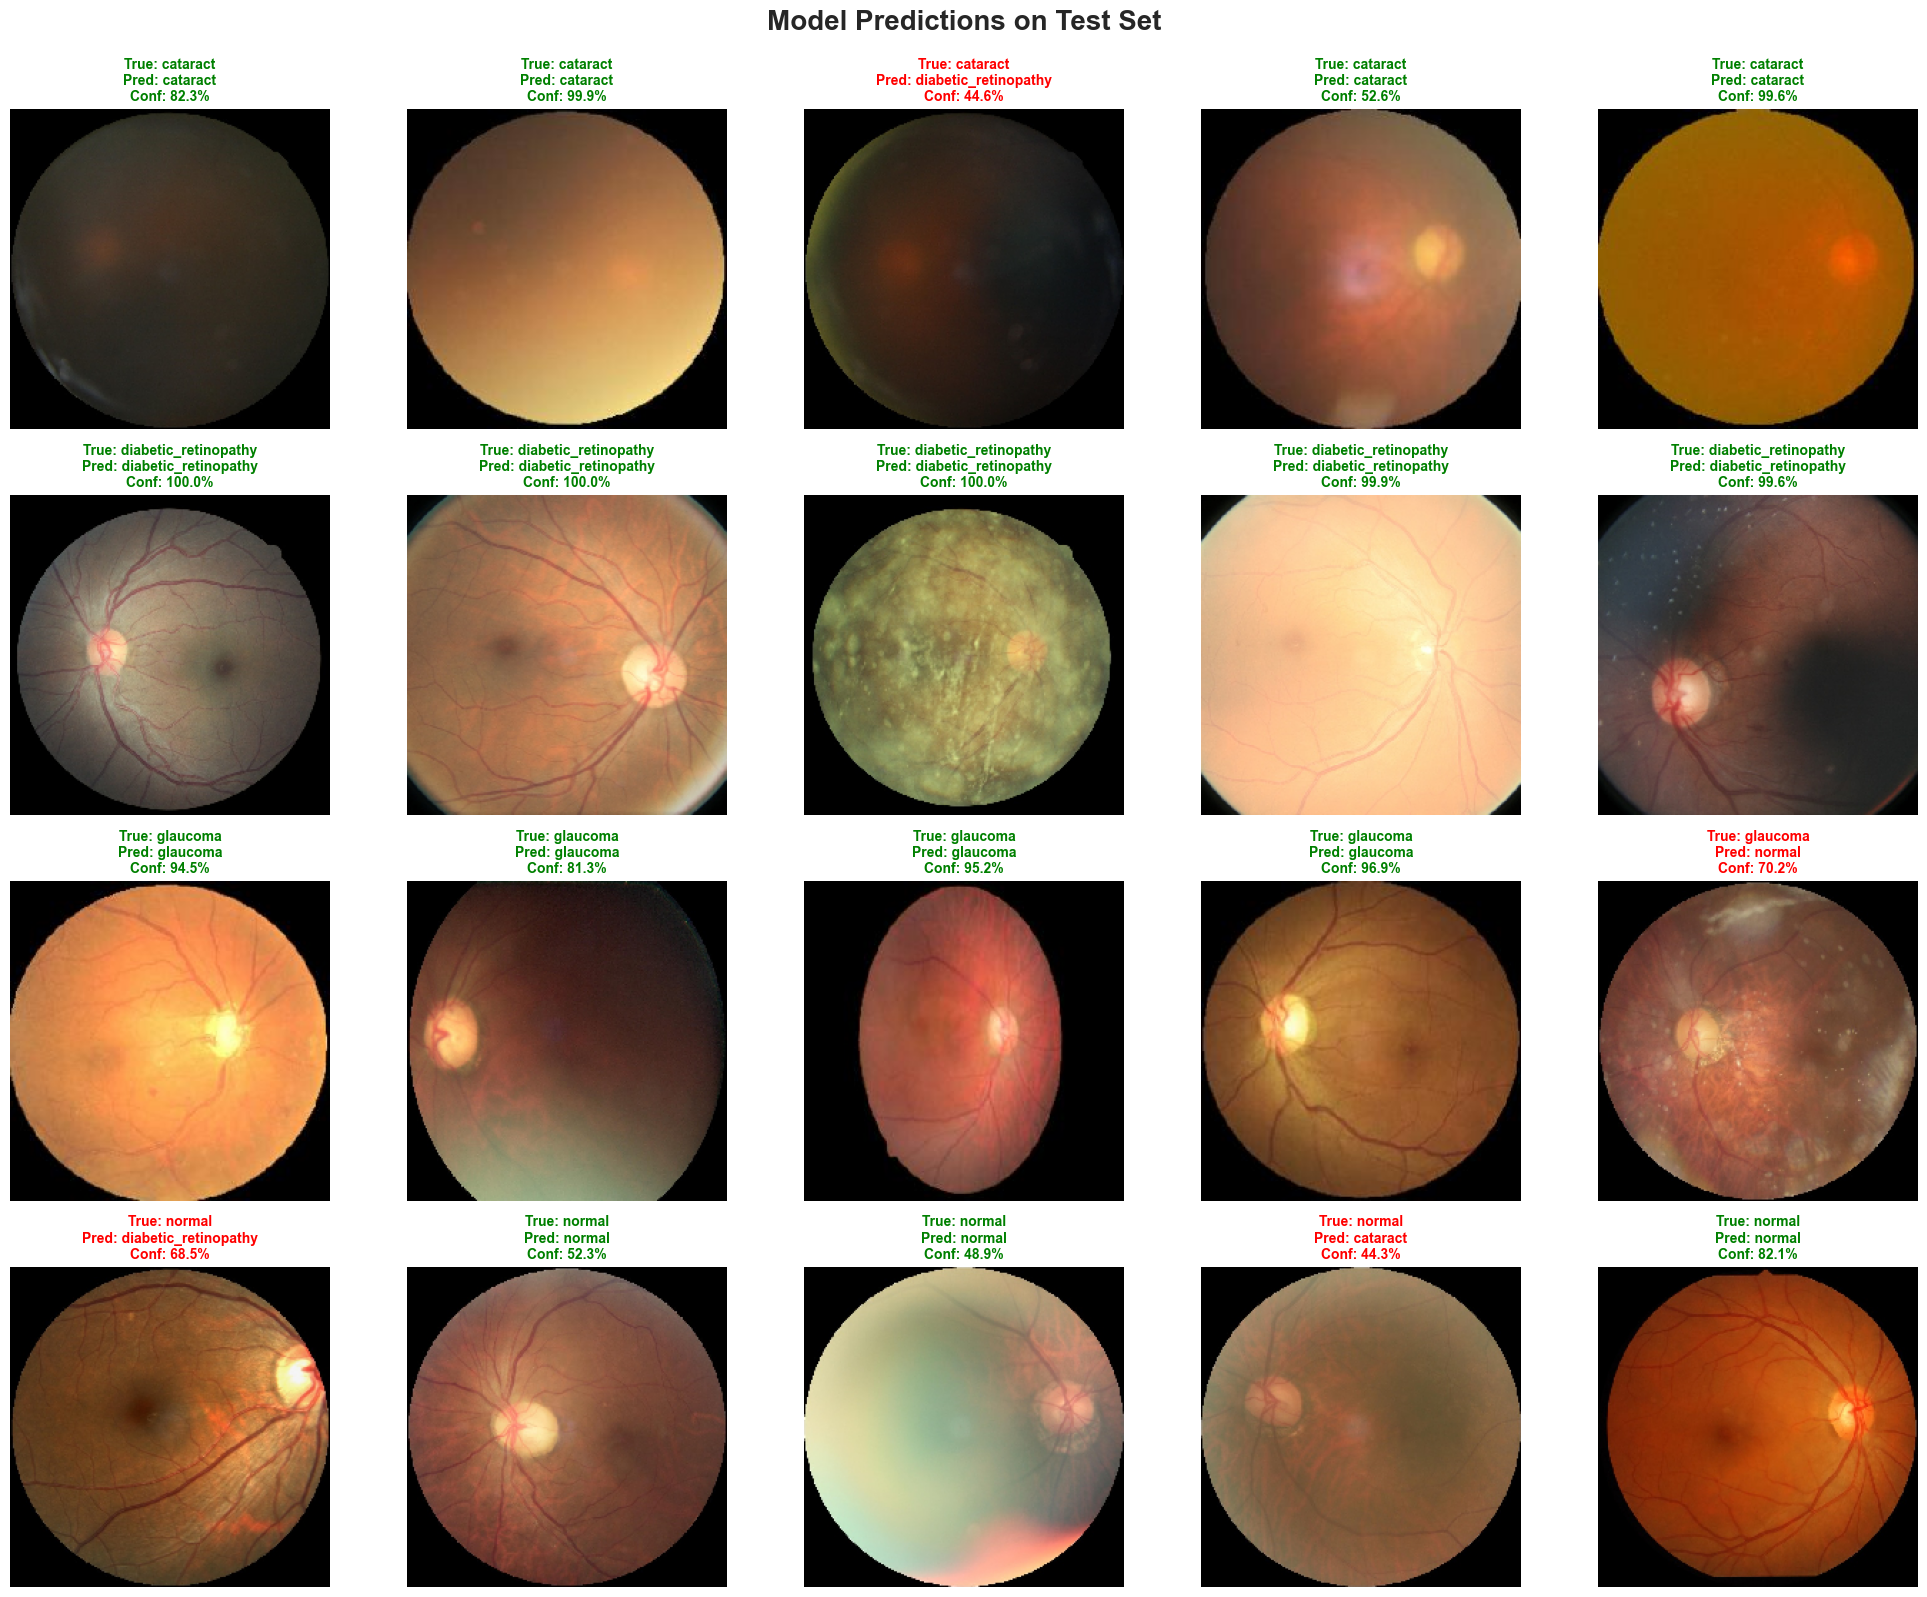

In [27]:
def predict_and_visualize(model, test_images, test_labels, class_names, samples_per_class=5):

    predictions = model.predict(test_images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    
    fig, axes = plt.subplots(len(class_names), samples_per_class, figsize=(20, 16))
    fig.suptitle('Model Predictions on Test Set', fontsize=20, fontweight='bold', y=0.995)
    
    for class_idx in range(len(class_names)):
        # Get indices of test images for this class
        class_indices = np.where(test_labels == class_idx)[0]
        
        if len(class_indices) < samples_per_class:
            selected_indices = class_indices
        else:
            selected_indices = np.random.choice(class_indices, samples_per_class, replace=False)
        
        for i, idx in enumerate(selected_indices):
            ax = axes[class_idx, i]
            ax.imshow(test_images[idx])
            
            true_label = class_names[test_labels[idx]]
            pred_label = class_names[predicted_classes[idx]]
            confidence = predictions[idx][predicted_classes[idx]] * 100
            
            # Color code: green for correct, red for incorrect
            color = 'green' if true_label == pred_label else 'red'
            
            title = f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.1f}%'
            ax.set_title(title, fontsize=10, color=color, fontweight='bold')
            ax.axis('off')
            
            if i == 0:
                ax.set_ylabel(class_names[class_idx].replace('_', ' ').title(), 
                            fontsize=13, fontweight='bold', rotation=0,
                            labelpad=80, ha='right')
    
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'predictions_visualization.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

# Visualize predictions

predict_and_visualize(model, X_test, y_test, CLASS_NAMES)

---
## 1️⃣6️⃣ Prediction Confidence Distribution

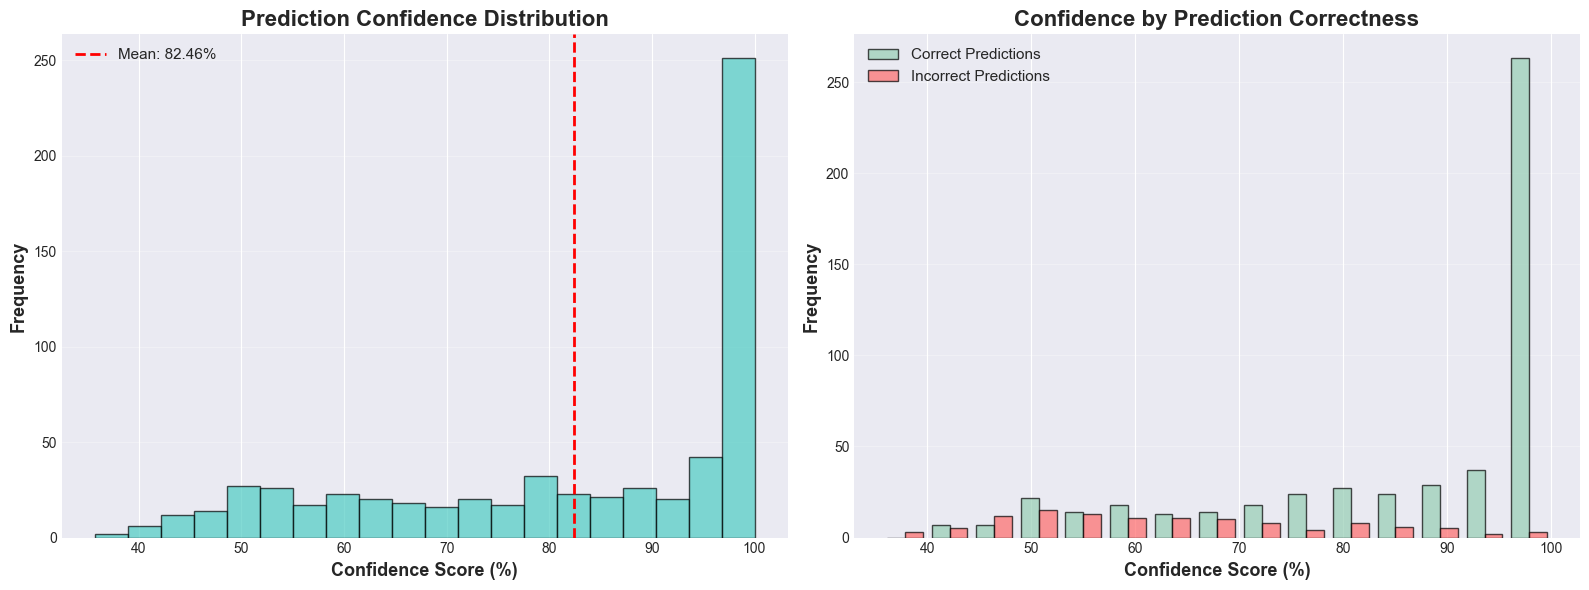

Overall Mean Confidence: 82.46%
Overall Median Confidence: 89.97%

Correct Predictions:
  Mean Confidence: 86.79%
  Median Confidence: 96.28%

Incorrect Predictions:
  Mean Confidence: 63.13%
  Median Confidence: 60.65%


In [31]:
# Analyze prediction confidence
confidence_scores = np.max(y_pred, axis=1) * 100
correct_predictions = (y_pred_classes == y_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall confidence distribution
axes[0].hist(confidence_scores, bins=20, color='#4ECDC4', edgecolor='black', alpha=0.7)
axes[0].axvline(confidence_scores.mean(), color='red', linestyle='--', 
               linewidth=2, label=f'Mean: {confidence_scores.mean():.2f}%')
axes[0].set_xlabel('Confidence Score (%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=13, fontweight='bold')
axes[0].set_title('Prediction Confidence Distribution', fontsize=16, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# Confidence by correctness
correct_conf = confidence_scores[correct_predictions]
incorrect_conf = confidence_scores[~correct_predictions]

axes[1].hist([correct_conf, incorrect_conf], bins=15, 
            label=['Correct Predictions', 'Incorrect Predictions'],
            color=['#96CEB4', '#FF6B6B'], edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Confidence Score (%)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=13, fontweight='bold')
axes[1].set_title('Confidence by Prediction Correctness', fontsize=16, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, 'confidence_distribution.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show()

# Print statistics

print(f"Overall Mean Confidence: {confidence_scores.mean():.2f}%")
print(f"Overall Median Confidence: {np.median(confidence_scores):.2f}%")
print(f"\nCorrect Predictions:")
print(f"  Mean Confidence: {correct_conf.mean():.2f}%")
print(f"  Median Confidence: {np.median(correct_conf):.2f}%")
print(f"\nIncorrect Predictions:")
print(f"  Mean Confidence: {incorrect_conf.mean():.2f}%")
print(f"  Median Confidence: {np.median(incorrect_conf):.2f}%")


---
## 1️⃣7️⃣ Summary of All Results

In [34]:
print(f"Test Accuracy: {test_accuracy*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"\nF1-Score (Macro): {f1_macro:.4f}")
print(f"F1-Score (Weighted): {f1_weighted:.4f}")
print(f"\nPrecision (Macro): {precision_macro:.4f}")
print(f"Recall (Macro): {recall_macro:.4f}")
print(f"\nROC AUC (Macro): {roc_auc_scores['macro']:.4f}")
print(f"ROC AUC (Micro): {roc_auc_scores['micro']:.4f}")

Test Accuracy: 81.67%
Test Loss: 0.4770

F1-Score (Macro): 0.8182
F1-Score (Weighted): 0.8178

Precision (Macro): 0.8218
Recall (Macro): 0.8169

ROC AUC (Macro): 0.9572
ROC AUC (Micro): 0.9613
